# Práctica 2.2 · Random forest: muchos árboles para priorizar hogares

Este cuaderno acompaña la clase «Random forest» y usa **los mismos hogares** de la práctica de árbol de decisión, para comparar un solo árbol con un bosque. Sigue el recorrido de la clase:

1. Datos y partición (igual que en el árbol) · 2. **Un árbol es inestable** · 3. Construir el bosque: **bootstrap, variables al azar y votación** · 4. **Error OOB**: una validación gratis · 5. ¿Cuántos árboles? · 6. Hiperparámetros con validación cruzada · 7. **Métricas**: línea base, logística, árbol y bosque · 8. **Importancia** por impureza y por permutación · 9. **Dependencia parcial** · 10. Entrenamiento frente a prueba

**Datos.** `datos/2-2-hogares-subsidio.xlsx`: 1.200 hogares **simulados con fines didácticos**; la variable objetivo es **pobre (Sí/No)**.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Datos y partición

Se prepara la base exactamente como en la práctica del árbol (misma función, misma semilla y misma partición estratificada 75/25), para que las comparaciones sean justas.

In [3]:
hog = pd.read_excel(DATOS / '2-2-hogares-subsidio.xlsx', sheet_name='hogares')
hog['es_pobre'] = (hog['pobre'] == 'Sí').astype(int)
def preparar(d):
    X = d[['personas', 'menores_5', 'adultos_mayores', 'educacion_jefe', 'ocupados', 'ingreso_pc', 'cuartos', 'hacinamiento']].copy()
    for c in ['jefe_mujer', 'acueducto', 'piso_tierra', 'internet']:
        X[c] = (d[c] == 'Sí').astype(int)
    X['rural'] = (d['zona'] == 'Rural').astype(int)
    return X.join(pd.get_dummies(d[['tipo_municipio', 'regimen_salud']], dtype=int)).astype(float)
X, y = preparar(hog), hog['es_pobre']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEMILLA, stratify=y)
print(f'{len(hog)} hogares, {y.mean():.1%} pobres · entrenamiento {len(Xtr)} · prueba {len(Xte)} · {X.shape[1]} variables')

1200 hogares, 32.8% pobres · entrenamiento 900 · prueba 300 · 19 variables


Es la misma base de la práctica del árbol: **1.200 hogares, el 32,8 % pobres**, con 900 para entrenar y 300 para la prueba, y las mismas 19 variables. Como la semilla y la partición son idénticas, las cifras del árbol y del bosque se pueden comparar directamente.

## 2. Un árbol es inestable

Un árbol profundo cambia mucho si cambian un poco los datos. Para verlo, se entrenan tres árboles con tres **muestras bootstrap** del entrenamiento: muestras del mismo tamaño, sacadas **con reemplazo** (algunos hogares se repiten y otros no salen).

In [4]:
rng = np.random.default_rng(SEMILLA)
arboles, preds = [], []
for b in range(3):
    idx = rng.integers(0, len(Xtr), len(Xtr))
    a = DecisionTreeClassifier(max_depth=6, random_state=b).fit(Xtr.iloc[idx], ytr.iloc[idx])
    arboles.append(a); preds.append(a.predict(Xte))
    t = a.tree_
    print(f'Árbol {b + 1}: {len(np.unique(idx))} hogares distintos ({len(np.unique(idx)) / len(Xtr):.1%}) · primer corte: {X.columns[t.feature[0]]} ≤ {t.threshold[0]:,.2f} · '
          f'segundo nivel: {X.columns[t.feature[t.children_left[0]]]} / {X.columns[t.feature[t.children_right[0]]]} · exactitud en prueba {accuracy_score(yte, preds[-1]):.3f}')
desacuerdo = (np.array(preds).std(axis=0) > 0).mean()
print(f'Los tres árboles no coinciden en {desacuerdo:.1%} de los hogares de prueba')

Árbol 1: 576 hogares distintos (64.0%) · primer corte: ingreso_pc ≤ 249,500.00 · segundo nivel: educacion_jefe / educacion_jefe · exactitud en prueba 0.880
Árbol 2: 579 hogares distintos (64.3%) · primer corte: ingreso_pc ≤ 424,000.00 · segundo nivel: ingreso_pc / ingreso_pc · exactitud en prueba 0.890
Árbol 3: 575 hogares distintos (63.9%) · primer corte: ingreso_pc ≤ 249,000.00 · segundo nivel: educacion_jefe / educacion_jefe · exactitud en prueba 0.873
Los tres árboles no coinciden en 18.0% de los hogares de prueba


Cada muestra bootstrap tiene 900 hogares, pero solo unos **576 son distintos (64 %)**: los demás se repiten, y un 36 % de los hogares queda por fuera. Con esas pequeñas diferencias, los tres árboles ya no son el mismo:

- **Primer corte:** el ingreso en 249.500, en 424.000 y en 249.000 pesos.
- **Segundo nivel:** usan variables distintas.
- **Exactitud en prueba:** 0,880, 0,890 y 0,873.
- **Desacuerdo:** los tres árboles no coinciden en el **18,0 % de los hogares de prueba**.

Eso es la **inestabilidad** de un árbol: cambia mucho con pequeños cambios en los datos.

## 3. Construir el bosque: bootstrap, variables al azar y votación

Un **random forest** (bosque aleatorio) repite esa idea cientos de veces y **combina** los árboles:

1. Cada árbol se entrena con una **muestra bootstrap** distinta.
2. En cada corte, cada árbol solo puede elegir entre un **subconjunto al azar de variables** (`max_features`). Así los árboles se parecen menos entre sí.
3. Para clasificar, los árboles **votan**: la probabilidad es la proporción de votos por «pobre» (en regresión se promedian).

Los errores de árboles distintos se compensan, y el bosque es mucho más estable que cualquiera de ellos.

In [5]:
bosque = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEMILLA, n_jobs=-1).fit(Xtr, ytr)
p_bosque = bosque.predict_proba(Xte)[:, 1]
votos = np.array([a.predict(Xte.values) for a in bosque.estimators_])
print(f'Exactitud en prueba: bosque {accuracy_score(yte, (p_bosque >= .5).astype(int)):.3f} · árboles sueltos: '
      f'mínimo {min(accuracy_score(yte, v) for v in votos):.3f}, promedio {np.mean([accuracy_score(yte, v) for v in votos]):.3f}, máximo {max(accuracy_score(yte, v) for v in votos):.3f}')
ej = pd.DataFrame({'votos por pobre': votos[:, :6].sum(axis=0).astype(int), 'de': len(votos), 'probabilidad': p_bosque[:6], 'real': yte.values[:6]})
ej

Exactitud en prueba: bosque 0.923 · árboles sueltos: mínimo 0.757, promedio 0.832, máximo 0.900


,votos por pobre,de,probabilidad,real
0,0,300,0.000,0
1,127,300,0.423,1
2,4,300,0.013,0
3,10,300,0.033,0
4,10,300,0.033,0
5,277,300,0.923,1


Entre los 300 árboles del bosque, la exactitud en prueba va de **0,757 a 0,900**, con un promedio de **0,832**. **El bosque acierta 0,923: más que el mejor de sus propios árboles.** Los errores de unos árboles los corrigen los demás al votar. La tabla muestra cómo se arma la probabilidad:

- El sexto hogar recibió **277 votos de 300** por «pobre», así que su probabilidad es **0,923**.
- El segundo recibió 127 votos: probabilidad de 0,423. Con el umbral de 0,5 queda como «no pobre», aunque es pobre. Es uno de los casos difíciles.

## 4. Error OOB: una validación gratis

Cada muestra bootstrap deja por fuera, en promedio, a un tercio de los hogares: son los **OOB** (*out-of-bag*, «fuera de la bolsa»). Cada hogar se puede evaluar solo con los árboles que **no** lo vieron. El resultado es una estimación del desempeño en datos nuevos, sin gastar la prueba.

In [6]:
print(f'Exactitud OOB (solo con entrenamiento): {bosque.oob_score_:.3f}')
print(f'Exactitud en prueba:                    {accuracy_score(yte, (p_bosque >= .5).astype(int)):.3f}')
print(f'AUC OOB: {roc_auc_score(ytr, bosque.oob_decision_function_[:, 1]):.3f} · AUC en prueba: {roc_auc_score(yte, p_bosque):.3f}')

Exactitud OOB (solo con entrenamiento): 0.884
Exactitud en prueba:                    0.923
AUC OOB: 0.952 · AUC en prueba: 0.955


Sin usar la prueba, el OOB estima una exactitud de **0,884** y un AUC de **0,952**. En prueba se obtuvieron 0,923 y **0,955**. El OOB es una estimación confiable, algo conservadora en exactitud y casi exacta en AUC. Sirve cuando hay pocos datos y no se quiere apartar una prueba, o para comparar configuraciones rápido.

## 5. ¿Cuántos árboles?

`n_estimators` es el número de árboles. Más árboles nunca empeoran el bosque, pero desde cierto punto ya no lo mejoran y solo cuestan tiempo. Se ve con el error OOB a medida que crece el bosque.

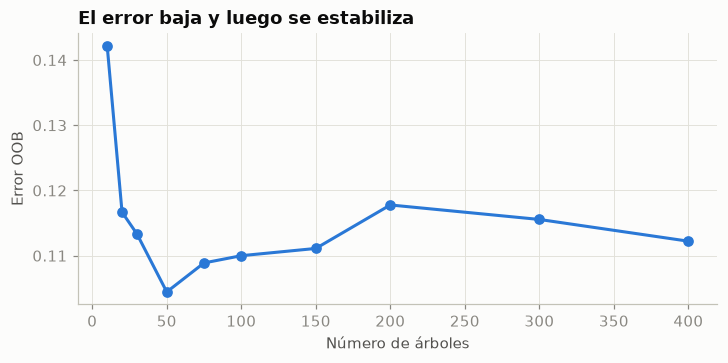

árboles,10,20,30,50,75,100,150,200,300,400
error OOB,0.142,0.117,0.113,0.104,0.109,0.110,0.111,0.118,0.116,0.112


In [7]:
errores = []
b = RandomForestClassifier(warm_start=True, oob_score=True, random_state=SEMILLA, n_jobs=-1)
for n in [10, 20, 30, 50, 75, 100, 150, 200, 300, 400]:
    b.set_params(n_estimators=n).fit(Xtr, ytr); errores.append((n, 1 - b.oob_score_))
err = pd.DataFrame(errores, columns=['árboles', 'error OOB']).set_index('árboles')
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(err.index, err['error OOB'], 'o-', color=AZUL); ax.set_xlabel('Número de árboles'); ax.set_ylabel('Error OOB')
ax.set_title('El error baja y luego se estabiliza'); plt.show()
err.T

El error OOB baja rápido al principio: de **0,142 con 10 árboles a 0,104 con 50**. Desde ahí se queda entre 0,104 y 0,118, con pequeñas oscilaciones por azar. Más árboles **no causan sobreajuste**; solo dejan de mejorar. Unos cientos de árboles bastan con estos datos, y por eso se usaron 300.

## 6. Hiperparámetros con validación cruzada

Los más importantes son:

- `max_features`: cuántas variables puede elegir cada corte. Pocas dan árboles más distintos entre sí.
- `min_samples_leaf`: el mínimo de hogares por hoja. Más alto da árboles más suaves.
- `max_depth`: la profundidad. Casi siempre se deja libre en un bosque.

Se eligen con validación cruzada en entrenamiento, usando el AUC.

In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
busq = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
                    {'max_features': ['sqrt', 0.3, 0.5, None], 'min_samples_leaf': [1, 5, 10]}, cv=cv, scoring='roc_auc').fit(Xtr, ytr)
print('Mejor combinación:', busq.best_params_, f'· AUC en validación cruzada = {busq.best_score_:.3f}')
tabla_cv = pd.DataFrame(busq.cv_results_)[['param_max_features', 'param_min_samples_leaf', 'mean_test_score']]
tabla_cv.pivot(index='param_max_features', columns='param_min_samples_leaf', values='mean_test_score')

Mejor combinación: {'max_features': 0.5, 'min_samples_leaf': 5} · AUC en validación cruzada = 0.956


param_min_samples_leaf,1,5,10
param_max_features,,,
NaN,0.950,0.955,0.955
0.300,0.948,0.954,0.953
0.500,0.951,0.956,0.955
sqrt,0.950,0.953,0.953


La mejor combinación fue **`max_features = 0,5`** (la mitad de las variables en cada corte) con **al menos 5 hogares por hoja**, con un AUC de validación cruzada de **0,956**. Lo más llamativo es que **todas las combinaciones quedan entre 0,948 y 0,956**. El bosque es poco sensible a sus hiperparámetros, a diferencia de un solo árbol, cuya profundidad cambiaba mucho el resultado. Es una de sus ventajas prácticas.

## 7. Métricas: línea base, logística, árbol y bosque

Se comparan en **prueba**. El árbol es el ajustado con validación cruzada, con la misma rejilla de la práctica de árboles.

In [9]:
def metricas(yv, p, u=0.5):
    h = (p >= u).astype(int)
    return {'exactitud': accuracy_score(yv, h), 'precisión': precision_score(yv, h, zero_division=0), 'sensibilidad': recall_score(yv, h),
            'F1': f1_score(yv, h), 'AUC': roc_auc_score(yv, p) if np.std(p) > 0 else 0.5}
arbol = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 5, 10, 20, 40],
                     'ccp_alpha': [0, 0.001, 0.003, 0.01]}, cv=cv, scoring='roc_auc').fit(Xtr, ytr).best_estimator_
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Xtr, ytr)
mejor = busq.best_estimator_
prob = {'Línea base (nadie es pobre)': np.zeros(len(yte)), 'Regresión logística': logit.predict_proba(Xte)[:, 1],
        'Árbol ajustado': arbol.predict_proba(Xte)[:, 1], 'Random forest': mejor.predict_proba(Xte)[:, 1]}
tabla = pd.DataFrame({m: metricas(yte, p) for m, p in prob.items()}).T
tabla

,exactitud,precisión,sensibilidad,F1,AUC
Línea base (nadie es pobre),0.673,0.000,0.000,0.000,0.500
Regresión logística,0.863,0.806,0.765,0.785,0.936
Árbol ajustado,0.917,0.854,0.898,0.876,0.954
Random forest,0.913,0.853,0.888,0.870,0.963


En prueba, frente a la línea base (exactitud 0,673, sin encontrar a ningún hogar pobre):

| Modelo | Exactitud | Sensibilidad | AUC |
|---|---|---|---|
| Regresión logística | 0,863 | 0,765 | 0,936 |
| Árbol ajustado | 0,917 | 0,898 | 0,954 |
| **Random forest** | 0,913 | 0,888 | **0,963** |

El bosque **ordena mejor el riesgo** (el AUC más alto) y supera con amplitud a la logística y al árbol suelto típico (0,832 de exactitud). Con el umbral de 0,5 queda prácticamente empatado con el árbol bien ajustado. Un árbol cuidadosamente podado puede acercarse al bosque, pero el bosque llega ahí **sin tanto ajuste** y con menos variabilidad.

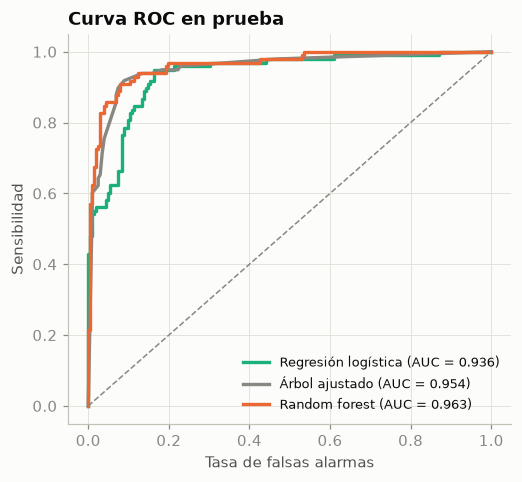

,Predijo: no pobre,Predijo: pobre
Real: no pobre,187,15
Real: pobre,11,87


In [10]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for nombre, color in [('Regresión logística', AQUA), ('Árbol ajustado', GRIS), ('Random forest', NARANJA)]:
    fpr, tpr, _ = roc_curve(yte, prob[nombre])
    ax.plot(fpr, tpr, color=color, lw=2.2, label=f'{nombre} (AUC = {roc_auc_score(yte, prob[nombre]):.3f})')
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1)
ax.set_xlabel('Tasa de falsas alarmas'); ax.set_ylabel('Sensibilidad'); ax.legend(loc='lower right', fontsize=8.5); ax.set_title('Curva ROC en prueba'); plt.show()
pd.DataFrame(confusion_matrix(yte, (prob['Random forest'] >= .5).astype(int)), index=['Real: no pobre', 'Real: pobre'], columns=['Predijo: no pobre', 'Predijo: pobre'])

La curva ROC del bosque va por encima de la de la logística en casi todo el recorrido, y es más suave que la del árbol: al promediar 200 árboles, las probabilidades toman muchos valores. Con el umbral de 0,5, de los 98 hogares pobres de prueba el bosque encuentra a **87** y se le escapan **11**; de los 202 no pobres, señala por error a 15.

## 8. Importancia: por impureza y por permutación

Hay dos formas de medir qué variables usa el bosque:

- **Por impureza** (`feature_importances_`): cuánto bajó el Gini, en promedio, en todos los árboles. Es rápida, pero favorece a las variables con muchos valores posibles.
- **Por permutación**: se desordena una variable en los datos de **prueba** y se mide cuánto cae el AUC. Si cae mucho, el modelo dependía de ella. Es más confiable.

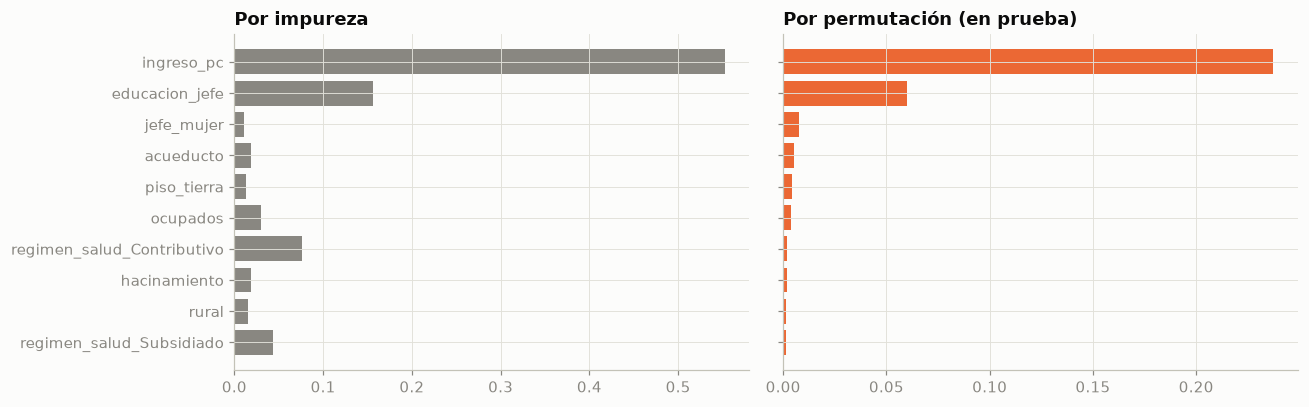

,impureza,permutación (caída del AUC)
ingreso_pc,0.552,0.237
educacion_jefe,0.156,0.060
jefe_mujer,0.010,0.007
acueducto,0.018,0.005
piso_tierra,0.013,0.004
ocupados,0.030,0.004
regimen_salud_Contributivo,0.076,0.002
hacinamiento,0.019,0.002
rural,0.015,0.001
regimen_salud_Subsidiado,0.044,0.001


In [11]:
pi = permutation_importance(mejor, Xte, yte, scoring='roc_auc', n_repeats=15, random_state=SEMILLA, n_jobs=-1)
imp = pd.DataFrame({'impureza': mejor.feature_importances_, 'permutación (caída del AUC)': pi.importances_mean}, index=X.columns)
imp = imp.sort_values('permutación (caída del AUC)', ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
top = imp.head(10).iloc[::-1]
axs[0].barh(top.index, top['impureza'], color=GRIS); axs[0].set_title('Por impureza')
axs[1].barh(top.index, top['permutación (caída del AUC)'], color=NARANJA); axs[1].set_title('Por permutación (en prueba)')
plt.tight_layout(); plt.show()
imp.head(10)

Las dos medidas coinciden en lo principal: el **ingreso por persona** es la variable dominante (impureza 0,552; caída del AUC al permutarla, **0,237**), seguido de la **educación de quien encabeza el hogar** (0,156 y **0,060**). Pero difieren en algo importante:

- **Por impureza**, el régimen contributivo aparece en el tercer lugar (0,076), y el subsidiado también figura (0,044).
- **Por permutación**, el contributivo casi no importa (0,002).

El régimen de salud va muy de la mano con el ingreso, así que repite información. La impureza lo premia porque el bosque lo usa en muchos cortes. La permutación muestra que, si se desordena, el modelo casi no pierde: el ingreso ya cuenta esa historia. Por eso se prefiere la importancia por permutación. Aparece además **quien encabeza el hogar es mujer** (0,007), que en la simulación pesa cuando hay pocos ocupados.

## 9. Dependencia parcial: ¿cómo cambia el riesgo con cada variable?

La importancia dice **cuánto** pesa una variable, pero no **en qué dirección**. El gráfico de **dependencia parcial** muestra cómo cambia, en promedio, la probabilidad predicha de pobreza al mover una sola variable y dejar las demás como están en los datos.

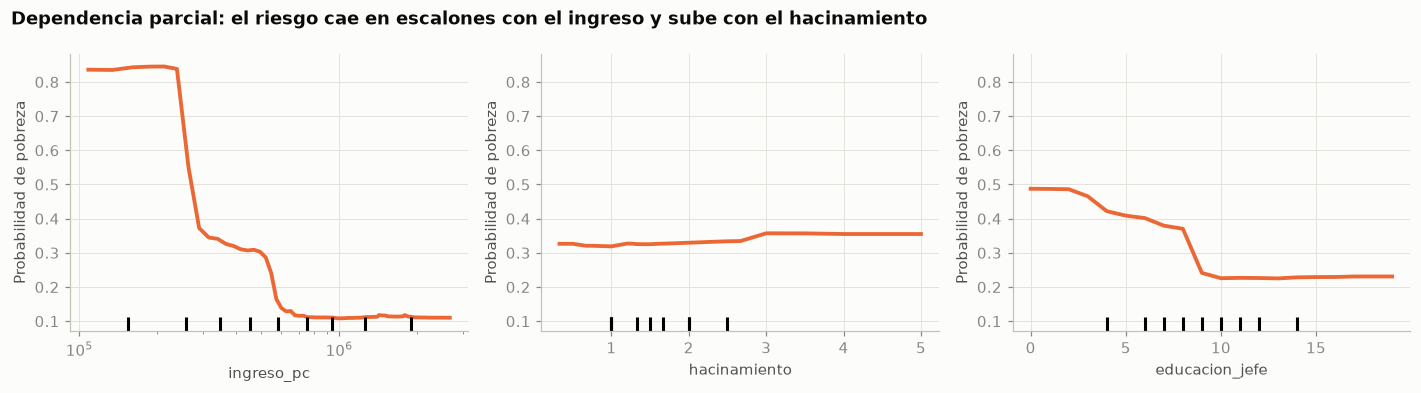

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
PartialDependenceDisplay.from_estimator(mejor, Xtr, ['ingreso_pc', 'hacinamiento', 'educacion_jefe'], ax=axs,
                                        line_kw={'color': NARANJA, 'lw': 2.5})
axs[0].set_xscale('log')
for a in axs: a.set_ylabel('Probabilidad de pobreza')
plt.suptitle('Dependencia parcial: el riesgo cae en escalones con el ingreso y sube con el hacinamiento', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

La dependencia parcial muestra la **forma** del efecto:

- **Ingreso:** la probabilidad media de pobreza cae de **0,84 con unos 110.000 pesos** por persona a 0,34 hacia los 340.000, y a 0,17 cerca de los 570.000. Desde unos 800.000 pesos se queda plana en torno a 0,11. Es una escalera con los umbrales con que se simularon los datos.
- **Educación:** baja poco a poco hasta los 8 años (de 0,49 a 0,37) y **cae de golpe a 0,24 al pasar de 9 años**. Luego se aplana.
- **Hacinamiento:** casi plana (de 0,32 a 0,36), porque solo importa cuando hay menores de 5 años.

Ninguna de estas formas es una recta. Por eso los modelos de árboles le ganan aquí a la regresión logística.

## 10. Entrenamiento frente a prueba

In [13]:
comp = pd.DataFrame({
    'Árbol ajustado · entrenamiento': metricas(ytr, arbol.predict_proba(Xtr)[:, 1]), 'Árbol ajustado · prueba': metricas(yte, prob['Árbol ajustado']),
    'Bosque · entrenamiento': metricas(ytr, mejor.predict_proba(Xtr)[:, 1]), 'Bosque · OOB': metricas(ytr, RandomForestClassifier(**{**mejor.get_params(), 'oob_score': True}).fit(Xtr, ytr).oob_decision_function_[:, 1]),
    'Bosque · prueba': metricas(yte, prob['Random forest'])}).T
comp

,exactitud,precisión,sensibilidad,F1,AUC
Árbol ajustado · entrenamiento,0.919,0.866,0.892,0.879,0.976
Árbol ajustado · prueba,0.917,0.854,0.898,0.876,0.954
Bosque · entrenamiento,0.944,0.921,0.909,0.915,0.990
Bosque · OOB,0.897,0.849,0.834,0.842,0.955
Bosque · prueba,0.913,0.853,0.888,0.870,0.963


La comparación muestra la diferencia entre los dos modelos:

- **Árbol ajustado:** casi igual en entrenamiento y en prueba (AUC 0,976 y 0,954).
- **Bosque:** casi perfecto en entrenamiento (**AUC 0,990**), pero esa cifra **no sirve para evaluarlo**, porque cada árbol vio esos hogares. Lo que cuenta es el OOB (0,955) y la prueba (0,963), que coinciden entre sí.

En un bosque, la brecha con el entrenamiento no indica un problema. Lo que hay que mirar es que el OOB y la prueba digan lo mismo.

## Conclusiones

| Pregunta | Respuesta con estos datos |
|---|---|
| ¿Por qué no basta un árbol? | Es inestable: tres árboles con muestras bootstrap distintas no coinciden en el 18 % de los hogares |
| ¿Qué hace el bosque? | Entrena cientos de árboles con **bootstrap** y **variables al azar** en cada corte, y los pone a **votar** |
| ¿Cuánto mejora? | Acierta 0,923 con 300 árboles, más que el mejor de sus árboles (0,900) y que el promedio de ellos (0,832) |
| ¿Cómo se valida sin la prueba? | Con el error **OOB**: AUC de 0,952, frente a 0,955 en prueba |
| ¿Cuántos árboles? | El error OOB se estabiliza desde unos 50; más árboles no sobreajustan |
| ¿Hiperparámetros? | `max_features` 0,5 y 5 hogares por hoja; todas las combinaciones quedan entre 0,948 y 0,956 de AUC |
| ¿Frente a los demás? | AUC en prueba: logística 0,936, árbol ajustado 0,954, **bosque 0,963** |
| ¿Qué variables pesan? | Por permutación: ingreso (0,237) y educación (0,060); la importancia por impureza sobrevalora el régimen de salud |
| ¿En qué dirección? | La dependencia parcial muestra escalones: la pobreza cae con el ingreso hasta unos 800.000 pesos y con la educación al pasar de 9 años |

El random forest cambia **explicabilidad por estabilidad y desempeño**. Ya no hay una regla que se pueda leer, pero la importancia por permutación y la dependencia parcial permiten explicar qué usa el modelo y cómo.

## Retos

1. **Muy pocos árboles.** Entrene bosques de 1, 5 y 25 árboles y compare su AUC en prueba con el del árbol ajustado. ¿Desde cuántos árboles el bosque le gana?
2. **Sin azar en las variables.** Use `max_features=None` (todas las variables en cada corte: *bagging*). ¿Cuánto se parecen ahora los árboles entre sí? ¿Cambia el AUC?
3. **Importancia con variables repetidas.** Agregue una copia del ingreso con un poco de ruido y repita las dos importancias. ¿Qué le pasa a la importancia del ingreso original?
4. **Interacción en la dependencia parcial.** Dibuje la dependencia parcial conjunta de `ingreso_pc` y `educacion_jefe` (`features=[('ingreso_pc', 'educacion_jefe')]`). ¿Se ve la interacción con la que se simularon los datos?
5. **Bosque de regresión.** Use `RandomForestRegressor` para predecir el `ingreso_pc`, y compare su MAE con el de un `DecisionTreeRegressor` y el de una regresión lineal.